# PAWN sensitivity analysis: thermal / hygroscopic mismatch index

Third global sensitivity method, run alongside Morris screening and Sobol indices.

**What PAWN measures.** Sobol splits the *variance* of the output. PAWN instead asks how much the whole *distribution* of the output changes when one input is fixed. For each input $x_i$:

1. Split the samples into $S$ equal-size slices by the value of $x_i$ (lowest values in slice 1, highest in slice $S$).
2. In each slice, compare the distribution of the output with the distribution over all samples, using the Kolmogorov–Smirnov (KS) distance: the largest vertical gap between the two cumulative distribution curves.
3. The PAWN index is the median of those $S$ KS distances (the maximum is also reported).

The index runs from 0 (fixing $x_i$ leaves the output distribution unchanged) to 1 (completely different). It does not assume the output has a meaningful variance, so it copes with skewed outputs and with the |σ| kink where the stress changes sign.

**Same samples as Sobol.** This notebook does not rerun the model. It reads the `Samples` sheet of each Sobol workbook and uses only the **A and B** Saltelli blocks (2N independent quasi-random samples). The AB blocks reuse columns of A, so they are not independent draws of the input space.

**Significance.** A dummy input (random numbers unrelated to the model) is added. Its PAWN index shows the noise level for this sample size; a real input whose bootstrap interval sits at or below the dummy's is treated as non-influential.

Reference: Pianosi, F. & Wagener, T. (2015, 2018), *Environmental Modelling & Software* 67 and 109.

## 1. Settings

Put this notebook in the same folder as the Sobol workbooks, or change the paths. If you rerun a Sobol case (for example after changing `Ea`), rerun this notebook too so PAWN uses the new samples.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

# Sobol workbooks produced by the sensitivity notebook (case name -> file)
CASES = {
    "A_exposure_arrhenius": Path("sobol_mismatch_A_exposure_arrhenius.xlsx"),
    "B_material":           Path("sobol_mismatch_B_material.xlsx"),
}

# Output to analyse:
#   "sigma"        |σ| mismatch index, the same output the Sobol indices used (default)
#   "sigma_signed" σ with its sign restored (tensile +, compressive -)
#   "eps_h", "eps_T"  the hygroscopic or thermal strain on its own
OUTPUT = "sigma"

BLOCKS   = ("A", "B")   # independent Saltelli blocks only
S        = 10           # number of conditioning slices per input
S_CHECK  = 20           # second slice count, to check the ranking does not depend on S
N_BOOT   = 300          # bootstrap replicates for the 95% confidence intervals
ALPHA    = 0.05         # significance level for the KS critical value
SEED     = 2026

SOBOL_NEGLIGIBLE = 0.01  # Sobol ST below this is treated as non-influential

# Optional: Morris mu* values for a three-way comparison, per case.
# They are only comparable if the Morris run used the SAME input ranges and fixed values
# as the Sobol case. Leave a case out (or the dict empty) to compare PAWN with Sobol only.
# Example: MORRIS_MU_STAR = {"B_material": {"D": 12.3, "C_sat": 6.1, ...}}
MORRIS_MU_STAR = {}

RESULTS_FILE = Path("pawn_results.xlsx")

## 2. Load the samples and the Sobol indices
Reading the `Samples` sheet takes a few seconds per workbook.

In [2]:
OUTPUT_COLUMNS = {
    "sigma": "Mismatch index (MPa)",
    "eps_h": "Hygroscopic strain (-)",
    "eps_T": "Thermal strain (-)",
}


def load_sobol_table(path):
    """Sobol S1/ST table from the workbook (rows above 'Sum')."""
    tab = pd.read_excel(path, sheet_name="Sobol S1 ST", header=2)
    rows = []
    for _, r in tab.iterrows():
        if pd.isna(r["Variable"]) or str(r["Variable"]).strip() == "Sum":
            break
        rows.append(r)
    tab = pd.DataFrame(rows).set_index("Variable")
    return tab[["S1", "S1 95% low", "S1 95% high", "ST", "ST 95% low", "ST 95% high"]].astype(float)


def load_case(path, output=OUTPUT, blocks=BLOCKS):
    """Return input matrix X, output Y, input names and the Sobol table for one case."""
    sobol = load_sobol_table(path)
    names = list(sobol.index)
    k = len(names)

    df = pd.read_excel(path, sheet_name="Samples")
    df = df[df["Saltelli block"].isin(blocks)]

    # Input columns follow 'Run' in the same order as the Sobol table
    in_cols = list(df.columns[1:1 + k])
    for n, c in zip(names, in_cols):
        if not str(c).startswith(f"{n} ("):
            raise ValueError(f"{path.name}: expected an input column for '{n}', found '{c}'")

    if output == "sigma_signed":
        strain = df[OUTPUT_COLUMNS["eps_h"]] + df[OUTPUT_COLUMNS["eps_T"]]
        Y = np.sign(strain.to_numpy()) * df[OUTPUT_COLUMNS["sigma"]].to_numpy()
    else:
        Y = df[OUTPUT_COLUMNS[output]].to_numpy(dtype=float)

    X = df[in_cols].to_numpy(dtype=float)
    return X, Y, names, sobol


data = {}
for case, path in CASES.items():
    X, Y, names, sobol = load_case(path)
    data[case] = dict(X=X, Y=Y, names=names, sobol=sobol)
    print(f"{case}: {X.shape[0]:,} samples (blocks {', '.join(BLOCKS)}), inputs: {', '.join(names)}")

A_exposure_arrhenius: 8,192 samples (blocks A, B), inputs: Time, Thickness, Temperature_K
B_material: 8,192 samples (blocks A, B), inputs: D, C_sat, beta_h, CTE_lam, E_eff, nu_eff


## 3. PAWN functions
Slices are formed from the *ranks* of each input (equal number of samples per slice), so it makes no difference whether an input was sampled on a linear or a log scale.

**About the confidence intervals.** Bootstrap resampling repeats some samples, which adds a little noise to every KS distance. The intervals are therefore shifted slightly upward and may not contain the point estimate for small indices (most visibly for the dummy). The shift is the same for every input, so the influential / non-influential test, which compares each input's interval with the dummy's interval, is still fair.

In [3]:
def ks_to_full(y_sorted, F_full, y_sub):
    """
    KS distance between the empirical CDF of y_sub and that of the full sample.
    y_sub is a subset of the full sample, so checking the CDFs at every full-sample
    point finds the largest gap exactly.
    """
    sub = np.sort(y_sub)
    F_sub = np.searchsorted(sub, y_sorted, side="right") / len(sub)
    return np.max(np.abs(F_sub - F_full))


def pawn_ks(X, Y, S):
    """KS distance for every input (rows) and conditioning slice (columns)."""
    y_sorted = np.sort(Y)
    F_full = np.searchsorted(y_sorted, y_sorted, side="right") / len(Y)
    ks = np.empty((X.shape[1], S))
    for i in range(X.shape[1]):
        order = np.argsort(X[:, i], kind="stable")
        for s, idx in enumerate(np.array_split(order, S)):
            ks[i, s] = ks_to_full(y_sorted, F_full, Y[idx])
    return ks


def ks_critical(n, S, alpha=ALPHA):
    """KS critical value for one slice (n/S points) against the full sample (n points)."""
    m = n / S
    c = np.sqrt(-np.log(alpha / 2) / 2)
    return c * np.sqrt((n + m) / (n * m))


def pawn_analysis(X, Y, names, S=S, n_boot=N_BOOT, seed=SEED):
    """
    PAWN indices (median and max KS over slices) with bootstrap 95% CIs.
    A dummy input, independent of the model, is appended to measure the noise level.
    """
    rng = np.random.default_rng(seed)
    n = len(Y)
    Xd = np.column_stack([X, rng.random(n)])
    labels = list(names) + ["Dummy"]

    ks = pawn_ks(Xd, Y, S)
    med, mx = np.median(ks, axis=1), np.max(ks, axis=1)

    boot_med = np.empty((n_boot, len(labels)))
    boot_max = np.empty((n_boot, len(labels)))
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        kb = pawn_ks(Xd[idx], Y[idx], S)
        boot_med[b], boot_max[b] = np.median(kb, axis=1), np.max(kb, axis=1)

    out = pd.DataFrame({
        "PAWN median": med,
        "median 95% low": np.percentile(boot_med, 2.5, axis=0),
        "median 95% high": np.percentile(boot_med, 97.5, axis=0),
        "PAWN max": mx,
        "max 95% low": np.percentile(boot_max, 2.5, axis=0),
        "max 95% high": np.percentile(boot_max, 97.5, axis=0),
    }, index=pd.Index(labels, name="Variable"))

    dummy_high = out.loc["Dummy", "median 95% high"]
    out["Influential"] = out["median 95% low"] > dummy_high
    out.loc["Dummy", "Influential"] = False
    return out, ks

## 4. Run PAWN
For each case: PAWN indices with 95% bootstrap intervals, the dummy (noise level) and the KS critical value for reference.

In [4]:
pawn = {}
for case, d in data.items():
    res, ks = pawn_analysis(d["X"], d["Y"], d["names"])
    pawn[case] = dict(res=res, ks=ks)
    print(f"\n=== {case}  (output: {OUTPUT}, S = {S}, n = {len(d['Y']):,}) ===")
    print(f"KS critical value at alpha = {ALPHA}: {ks_critical(len(d['Y']), S):.4f}")
    display(res.round(4))

    # KS distance in each slice (slice 1 = lowest input values). An input whose effect is
    # confined to part of its range shows large values in only a few slices; the median
    # then understates it, and the max is the better guide.
    per_slice = pd.DataFrame(ks, index=res.index, columns=[f"slice {s + 1}" for s in range(S)])
    print("KS distance per slice (slice 1 = lowest input values):")
    display(per_slice.round(3))


=== A_exposure_arrhenius  (output: sigma, S = 10, n = 8,192) ===
KS critical value at alpha = 0.05: 0.0498


,PAWN median,median 95% low,median 95% high,PAWN max,max 95% low,max 95% high,Influential
Variable,,,,,,,
Time,0.1519,0.1485,0.1722,0.4049,0.3817,0.4370,True
Thickness,0.1130,0.1035,0.1358,0.1749,0.1598,0.2042,True
Temperature_K,0.4547,0.4440,0.4671,0.7853,0.7772,0.7916,True
Dummy,0.0278,0.0313,0.0493,0.0484,0.0457,0.0892,False


KS distance per slice (slice 1 = lowest input values):


,slice 1,slice 2,slice 3,slice 4,slice 5,slice 6,slice 7,slice 8,slice 9,slice 10
Variable,,,,,,,,,,
Time,0.405,0.280,0.177,0.089,0.110,0.144,0.154,0.150,0.157,0.148
Thickness,0.148,0.150,0.105,0.092,0.051,0.043,0.068,0.121,0.135,0.175
Temperature_K,0.455,0.455,0.447,0.429,0.395,0.358,0.454,0.560,0.672,0.785
Dummy,0.033,0.024,0.025,0.017,0.036,0.027,0.048,0.014,0.028,0.040



=== B_material  (output: sigma, S = 10, n = 8,192) ===
KS critical value at alpha = 0.05: 0.0498


,PAWN median,median 95% low,median 95% high,PAWN max,max 95% low,max 95% high,Influential
Variable,,,,,,,
D,0.2396,0.2252,0.2632,0.3621,0.3391,0.3965,True
C_sat,0.1548,0.1331,0.1712,0.2512,0.2279,0.2798,True
beta_h,0.1181,0.1044,0.1419,0.2220,0.2000,0.2548,True
CTE_lam,0.2496,0.2309,0.2681,0.3612,0.3467,0.3855,True
E_eff,0.1388,0.1245,0.1625,0.2770,0.2599,0.3104,True
nu_eff,0.0349,0.0358,0.0553,0.0512,0.0524,0.0922,False
Dummy,0.0267,0.0292,0.0457,0.0385,0.0435,0.0771,False


KS distance per slice (slice 1 = lowest input values):


,slice 1,slice 2,slice 3,slice 4,slice 5,slice 6,slice 7,slice 8,slice 9,slice 10
Variable,,,,,,,,,,
D,0.324,0.297,0.227,0.181,0.107,0.071,0.145,0.252,0.310,0.362
C_sat,0.251,0.185,0.150,0.066,0.037,0.061,0.076,0.160,0.162,0.210
beta_h,0.222,0.158,0.112,0.068,0.029,0.040,0.089,0.124,0.145,0.178
CTE_lam,0.273,0.260,0.263,0.188,0.097,0.073,0.151,0.239,0.309,0.361
E_eff,0.277,0.200,0.131,0.066,0.032,0.061,0.115,0.146,0.174,0.219
nu_eff,0.047,0.039,0.041,0.023,0.021,0.028,0.030,0.031,0.051,0.041
Dummy,0.029,0.021,0.026,0.017,0.029,0.027,0.038,0.026,0.019,0.035


## 5. Robustness to the number of slices
The ranking should not depend on the choice of S. The median KS distance tends to fall slightly as S increases, so compare the order rather than the values.

In [5]:
for case, d in data.items():
    res_chk, _ = pawn_analysis(d["X"], d["Y"], d["names"], S=S_CHECK, n_boot=50)
    a = pawn[case]["res"].loc[d["names"], "PAWN median"]
    b = res_chk.loc[d["names"], "PAWN median"]
    tab = pd.DataFrame({
        f"PAWN (S={S})": a, f"rank (S={S})": a.rank(ascending=False).astype(int),
        f"PAWN (S={S_CHECK})": b, f"rank (S={S_CHECK})": b.rank(ascending=False).astype(int),
    })
    rho = spearmanr(a, b).statistic
    print(f"\n=== {case}: Spearman rank correlation between S={S} and S={S_CHECK}: {rho:.3f}")
    display(tab.round(4))


=== A_exposure_arrhenius: Spearman rank correlation between S=10 and S=20: 1.000


,PAWN (S=10),rank (S=10),PAWN (S=20),rank (S=20)
Variable,,,,
Time,0.1519,2,0.1542,2
Thickness,0.1130,3,0.1158,3
Temperature_K,0.4547,1,0.4571,1



=== B_material: Spearman rank correlation between S=10 and S=20: 1.000


,PAWN (S=10),rank (S=10),PAWN (S=20),rank (S=20)
Variable,,,,
D,0.2396,2,0.2471,2
C_sat,0.1548,3,0.1556,3
beta_h,0.1181,5,0.1205,5
CTE_lam,0.2496,1,0.2538,1
E_eff,0.1388,4,0.1423,4
nu_eff,0.0349,6,0.0412,6


## 6. Agreement with Sobol
The methods use different scales, so they are compared by **ranking** and by which inputs they classify as non-influential:

- **Spearman ρ:** +1 means the two methods rank the inputs in the same order. With only three inputs (Case A), ρ can only take a few values (±1, ±0.5), so read it together with the table.
- **Top input:** whether both methods put the same input first.
- **Non-influential set:** Sobol ST < `SOBOL_NEGLIGIBLE`; PAWN not distinguishable from the dummy

In [6]:
def agreement(case):
    names = data[case]["names"]
    sobol = data[case]["sobol"]
    res = pawn[case]["res"]

    scores = {"Sobol ST": sobol.loc[names, "ST"], "PAWN": res.loc[names, "PAWN median"]}
    if case in MORRIS_MU_STAR:
        scores["Morris mu*"] = pd.Series(MORRIS_MU_STAR[case]).reindex(names)

    tab = pd.DataFrame(scores)
    for m in list(scores):
        tab[f"rank {m}"] = tab[m].rank(ascending=False, method="min").astype(int)
    tab["Sobol: negligible"] = tab["Sobol ST"] < SOBOL_NEGLIGIBLE
    tab["PAWN: negligible"] = ~res.loc[names, "Influential"].astype(bool)

    methods = list(scores)
    pairs = []
    for i in range(len(methods)):
        for j in range(i + 1, len(methods)):
            m1, m2 = methods[i], methods[j]
            pairs.append({
                "Comparison": f"{m1} vs {m2}",
                "Spearman rho": spearmanr(tab[m1], tab[m2]).statistic,
                "Same top input": tab[m1].idxmax() == tab[m2].idxmax(),
                "Top-3 overlap": len(set(tab[m1].nlargest(3).index) & set(tab[m2].nlargest(3).index)),
            })
    pairs = pd.DataFrame(pairs)

    same_negl = (tab["Sobol: negligible"] == tab["PAWN: negligible"]).all()
    return tab, pairs, same_negl


agree = {}
for case in data:
    tab, pairs, same_negl = agreement(case)
    agree[case] = (tab, pairs)
    print(f"\n=== {case} ===")
    display(tab.round(4))
    display(pairs.round(3))
    print("Sobol and PAWN agree on which inputs are non-influential:", same_negl)


=== A_exposure_arrhenius ===


,Sobol ST,PAWN,rank Sobol ST,rank PAWN,Sobol: negligible,PAWN: negligible
Variable,,,,,,
Time,0.5909,0.1519,1,2,False,False
Thickness,0.3179,0.1130,3,3,False,False
Temperature_K,0.5339,0.4547,2,1,False,False


,Comparison,Spearman rho,Same top input,Top-3 overlap
0,Sobol ST vs PAWN,0.5,False,3


Sobol and PAWN agree on which inputs are non-influential: True

=== B_material ===


,Sobol ST,PAWN,rank Sobol ST,rank PAWN,Sobol: negligible,PAWN: negligible
Variable,,,,,,
D,0.4547,0.2396,1,2,False,False
C_sat,0.2202,0.1548,2,3,False,False
beta_h,0.1807,0.1181,5,5,False,False
CTE_lam,0.1884,0.2496,4,1,False,False
E_eff,0.2122,0.1388,3,4,False,False
nu_eff,0.0065,0.0349,6,6,True,True


,Comparison,Spearman rho,Same top input,Top-3 overlap
0,Sobol ST vs PAWN,0.657,False,2


Sobol and PAWN agree on which inputs are non-influential: True


## 7. Figures
1. PAWN indices with 95% intervals; the shaded band is the dummy's interval (noise level).
2. Indices from each method scaled so the largest input = 1, for a side-by-side view of the rankings.
3. Conditional CDFs: each thin line is the output distribution within one slice of the input (light = low input values, dark = high). The dashed line is the distribution over all samples. The more the lines fan out, the more influential the input.

In [7]:
# Chart styling
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]          # Sobol, PAWN, Morris
SLICE_CMAP = LinearSegmentedColormap.from_list("slices", ["#86b6ef", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

OUT_LABEL = {"sigma": "|σ| mismatch index (MPa)", "sigma_signed": "σ mismatch index (MPa)",
             "eps_h": "hygroscopic strain (–)", "eps_T": "thermal strain (–)"}[OUTPUT]

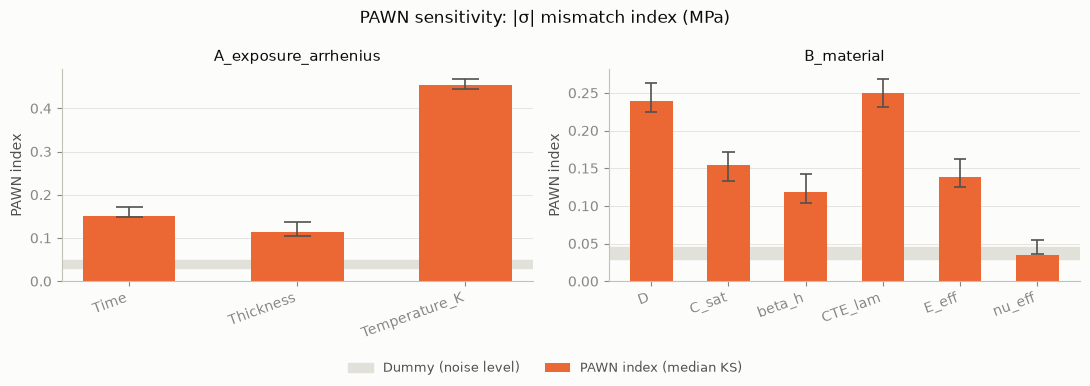

In [8]:
# Figure 1: PAWN indices with confidence intervals and the dummy noise band
fig, axes = plt.subplots(1, len(data), figsize=(5.5 * len(data), 3.8))
axes = np.atleast_1d(axes)
for ax, (case, d) in zip(axes, data.items()):
    res = pawn[case]["res"]
    names = d["names"]
    v = res.loc[names, "PAWN median"].to_numpy()
    lo = res.loc[names, "median 95% low"].to_numpy()
    hi = res.loc[names, "median 95% high"].to_numpy()
    x = np.arange(len(names))
    ax.axhspan(res.loc["Dummy", "median 95% low"], res.loc["Dummy", "median 95% high"],
               color=GRID, zorder=0, label="Dummy (noise level)")
    ax.bar(x, v, width=0.55, color=SERIES[1], zorder=2, label="PAWN index (median KS)")
    # 95% bootstrap interval drawn as a range (see the note in section 3 on its upward shift)
    ax.vlines(x, lo, hi, color=INK_2, lw=1.2, zorder=3)
    ax.hlines(np.r_[lo, hi], np.r_[x, x] - 0.08, np.r_[x, x] + 0.08, color=INK_2, lw=1.2, zorder=3)
    ax.set_xticks(x, names, rotation=20, ha="right")
    ax.set_ylabel("PAWN index")
    ax.set_title(case)
    ax.grid(axis="x", visible=False)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, fontsize=9)
fig.suptitle(f"PAWN sensitivity: {OUT_LABEL}", fontsize=12, color=INK)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

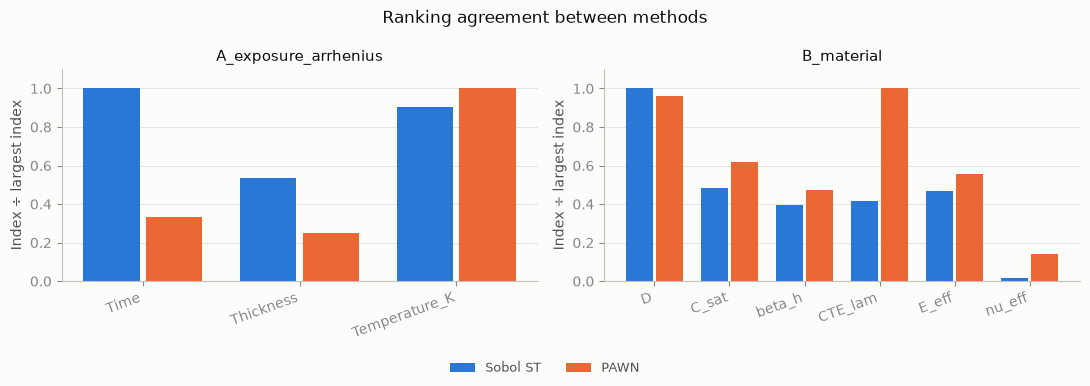

In [9]:
# Figure 2: methods side by side, each scaled so its largest index = 1
fig, axes = plt.subplots(1, len(data), figsize=(5.5 * len(data), 3.8))
axes = np.atleast_1d(axes)
for ax, case in zip(axes, data):
    tab = agree[case][0]
    methods = [m for m in ["Sobol ST", "PAWN", "Morris mu*"] if m in tab]
    x = np.arange(len(tab))
    w = 0.8 / len(methods)
    for j, m in enumerate(methods):
        ax.bar(x + (j - (len(methods) - 1) / 2) * w, tab[m] / tab[m].max(),
               width=w * 0.9, color=SERIES[[0, 1, 2][["Sobol ST", "PAWN", "Morris mu*"].index(m)]],
               label=m, zorder=2)
    ax.set_xticks(x, tab.index, rotation=20, ha="right")
    ax.set_ylabel("Index ÷ largest index")
    ax.set_ylim(0, 1.1)
    ax.set_title(case)
    ax.grid(axis="x", visible=False)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(l), fontsize=9)
fig.suptitle("Ranking agreement between methods", fontsize=12, color=INK)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

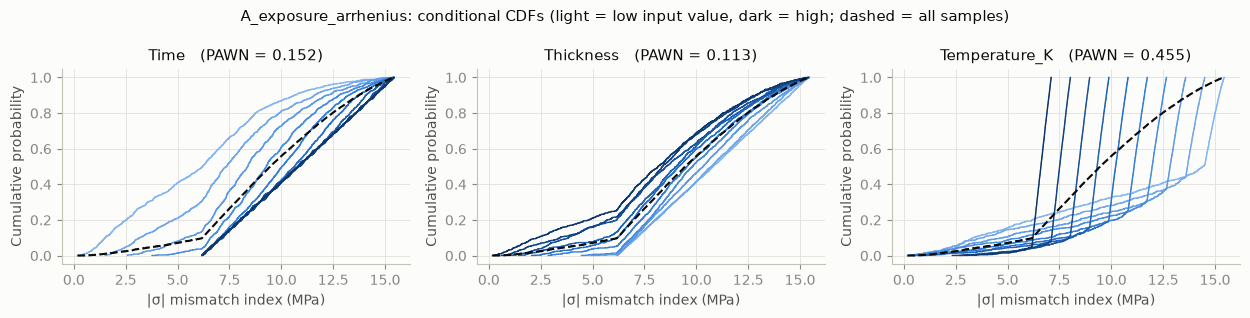

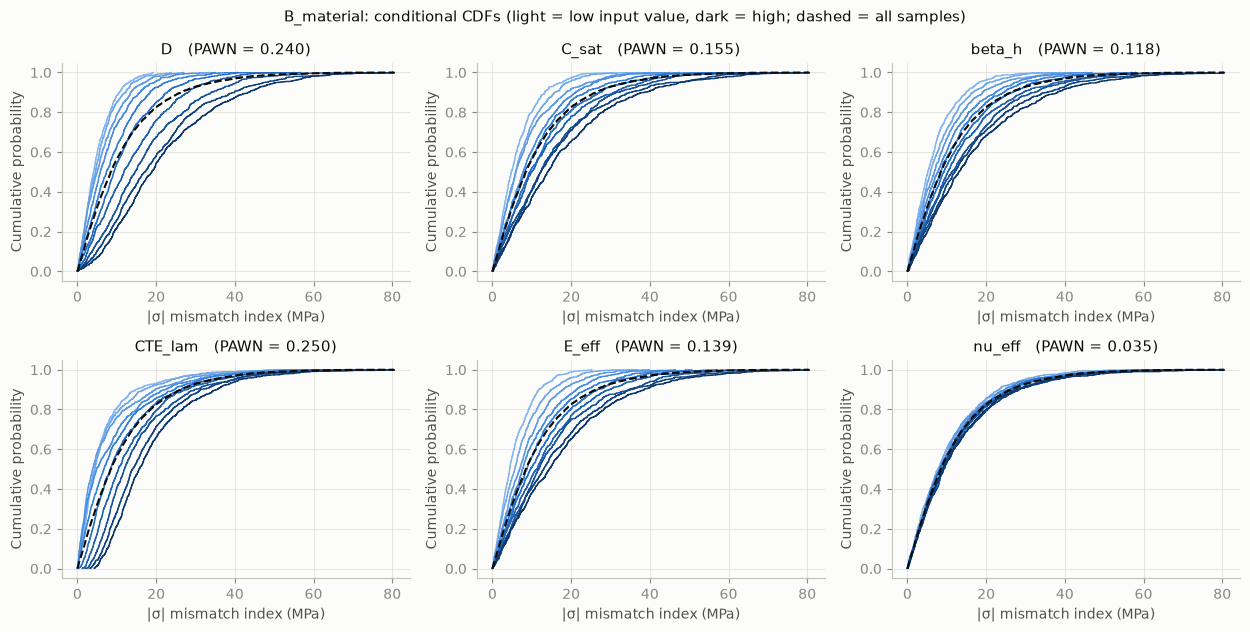

In [10]:
# Figure 3: conditional CDFs for each input (one figure per case)
for case, d in data.items():
    X, Y, names = d["X"], d["Y"], d["names"]
    k = len(names)
    ncol = 3
    nrow = int(np.ceil(k / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.2 * nrow), squeeze=False)
    y_all = np.sort(Y)
    F_all = np.arange(1, len(Y) + 1) / len(Y)
    for i, ax in enumerate(axes.flat):
        if i >= k:
            ax.axis("off")
            continue
        order = np.argsort(X[:, i], kind="stable")
        slices = np.array_split(order, S)
        for s, idx in enumerate(slices):
            ys = np.sort(Y[idx])
            ax.step(ys, np.arange(1, len(ys) + 1) / len(ys), where="post",
                    color=SLICE_CMAP(s / (S - 1)), lw=1)
        ax.step(y_all, F_all, where="post", color=INK, lw=1.5, ls="--")
        ax.set_title(f"{names[i]}   (PAWN = {pawn[case]['res'].loc[names[i], 'PAWN median']:.3f})")
        ax.set_xlabel(OUT_LABEL)
        ax.set_ylabel("Cumulative probability")
    fig.suptitle(f"{case}: conditional CDFs (light = low input value, dark = high; dashed = all samples)",
                 fontsize=11, color=INK)
    fig.tight_layout()
    plt.show()

## 8. Save the results
Writes one sheet of PAWN indices and one sheet of method agreement per case.

In [11]:
with pd.ExcelWriter(RESULTS_FILE, engine="openpyxl") as xw:
    pd.DataFrame({
        "Setting": ["Output", "Saltelli blocks used", "Slices S", "Bootstrap replicates",
                    "Significance level", "Sobol negligible threshold"],
        "Value": [OUTPUT, ", ".join(BLOCKS), S, N_BOOT, ALPHA, SOBOL_NEGLIGIBLE],
    }).to_excel(xw, sheet_name="Settings", index=False)
    for case in data:
        short = case[:20]
        pawn[case]["res"].to_excel(xw, sheet_name=f"PAWN {short}")
        tab, pairs = agree[case]
        tab.to_excel(xw, sheet_name=f"Agree {short}")
        pairs.to_excel(xw, sheet_name=f"Agree {short}", startrow=len(tab) + 3, index=False)
print(f"Saved {RESULTS_FILE}")

Saved pawn_results.xlsx


## Notes on interpreting the results
- **Compare rankings, not values.** A PAWN index of 0.3 and a Sobol ST of 0.3 do not mean the same thing.
- **Expected differences.** If an input ranks higher in PAWN than in Sobol, it mostly shifts the shape or tails of the output distribution (for example the high-stress cases) rather than its variance. If it ranks lower, its effect is concentrated in a few large deviations that dominate the variance.
- **Same input space.** PAWN uses exactly the Sobol samples, so the comparison is like for like. A Morris comparison is only valid if the Morris run used the same ranges and fixed values.
- **Conditional results.** As with Sobol, the indices hold only for the chosen ranges and the inputs held fixed in each case.